# Домашняя работа №6
Мацюк Константин Владимирович  
НПИбд-02-25  
1032253640

## Система Лоренца

$$
\frac{dx}{dt}=10(y-x), \qquad
\frac{dy}{dt}=28x-y-xz, \qquad
\frac{dz}{dt}=xy-\frac{8}{3}z.
$$

$$
x(0)=3.051522, \qquad y(0)=1.582542, \qquad z(0)=15.62388.
$$

In [1]:
load('fdm.sage')
var('x,y,z,t')

s = 10
r = 28
b = 8/3
u0 = [3.051522, 1.582542, 15.62388]

pr = Initial_problem(
    [x,y,z],
    [s*(y-x), r*x-y-x*z, x*y-b*z],
    u0,
    20
)

dt = 0.01
sol = erk(pr, N=round(pr.T/dt))

## Задание 1

Для системы Лоренца с указанными начальными условиями нарисуйте график $y$ от $t$ на отрезке $0<t<20$ при $\Delta t=0.01$.

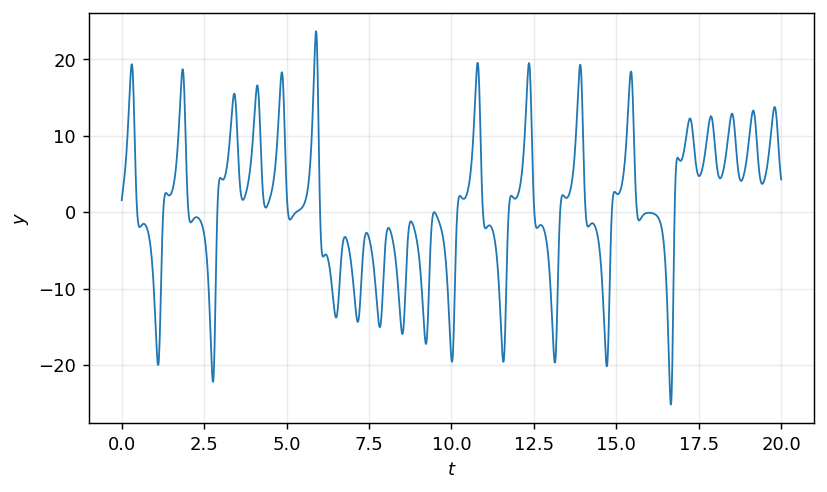

In [2]:
sol.plot(t,y,axes_labels=['$t$','$y$'])

**Вывод:** на отрезке $0<t<20$ функция $y(t)$ совершает нерегулярные колебания, характерные для системы Лоренца.

## Задание 2

Для системы Лоренца с указанными начальными условиями нарисуйте график $x+y$ от $t$ на отрезке $0<t<20$ при $\Delta t=0.01$.

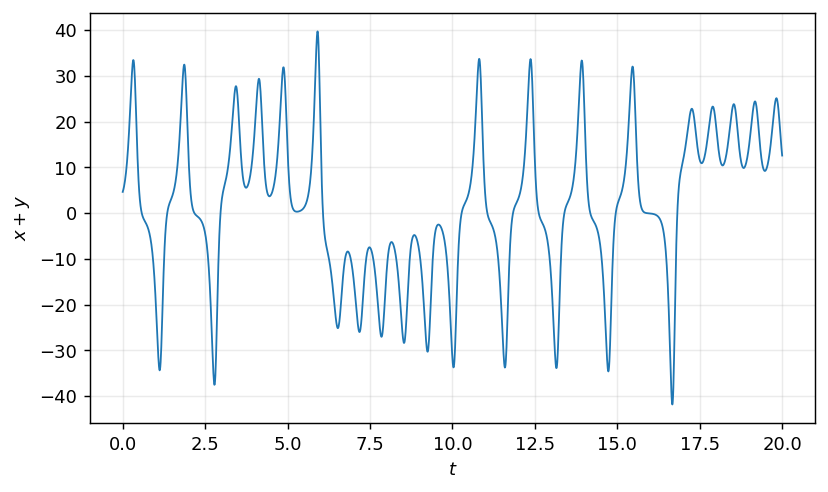

In [3]:
sol.plot(t,x+y,axes_labels=['$t$','$x+y$'])

**Вывод:** величина $x+y$ не сохраняется и также совершает нерегулярные колебания.

## Задание 3

Для системы Лоренца с указанными начальными условиями нарисуйте проекцию траектории на плоскость $xy$ при $\Delta t=0.01$.

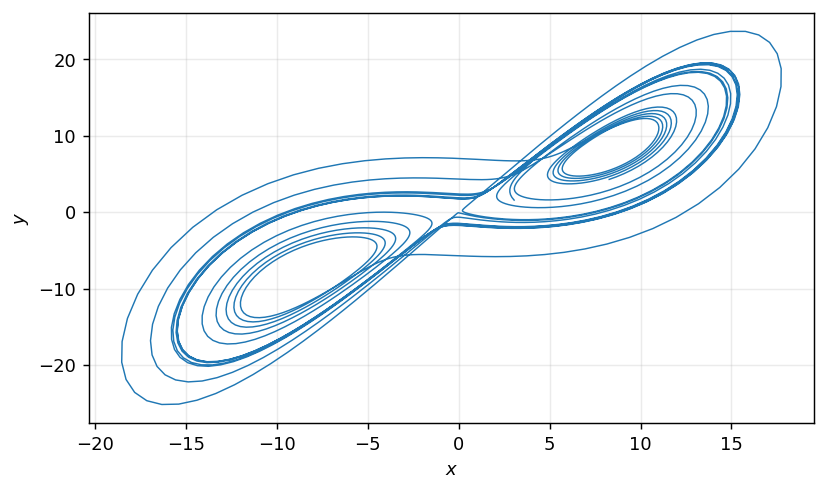

In [4]:
sol.plot(x,y,axes_labels=['$x$','$y$'])

**Вывод:** проекция имеет два крыла аттрактора Лоренца; траектория переходит между ними.

## Задание 4

Для системы Лоренца с указанными начальными условиями нарисуйте диаграмму Ричардсона для $x$ при $t=1$ и $t=5$. При каких $\Delta t$ применим метод Ричардсона?

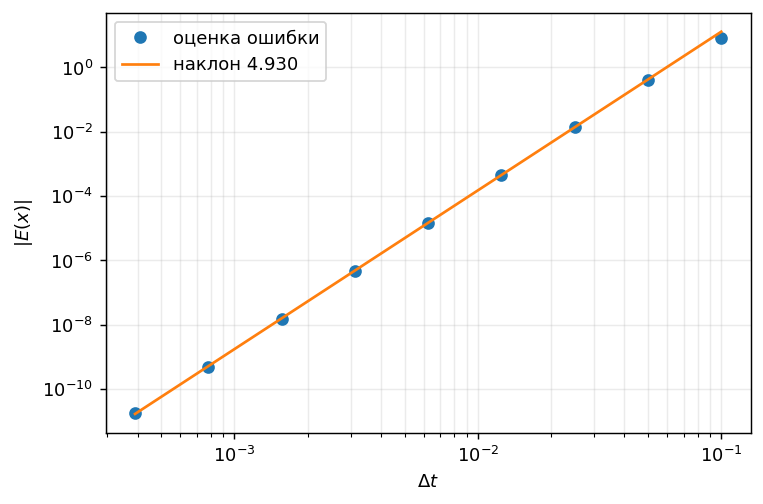

In [5]:
prR = Initial_problem(
    [x,y,z],
    [s*(y-x), r*x-y-x*z, x*y-b*z],
    u0,
    5
)

Ns = [50*2^n for n in range(10)]
L = [erk(prR,N=N,field=RealField(100)) for N in Ns]

richardson_plot(L,x,1,nmin=1)

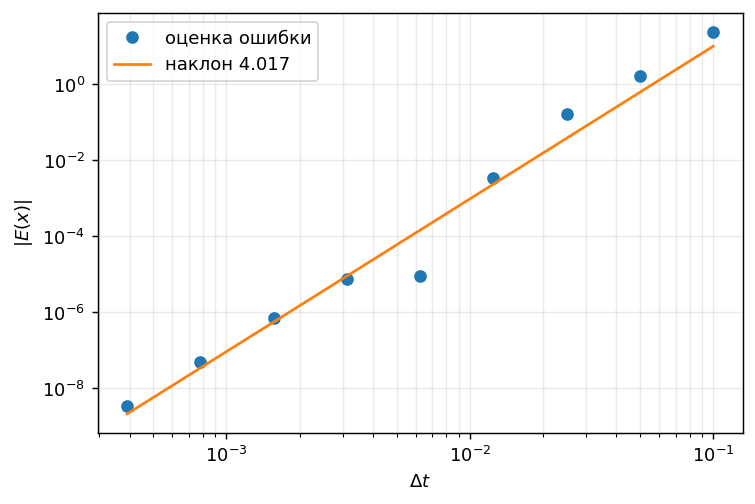

In [6]:
richardson_plot(L,x,5,nmin=2)

**Вывод:** при $t=1$ точки образуют прямолинейный участок примерно при $\Delta t\leq0.05$; наклон аппроксимирующей прямой равен $4.93$. При $t=5$ прямолинейный участок с наклоном $4.02\approx4$ начинается примерно при $\Delta t\leq0.025$. Для оценки $x(5)$ используем $\Delta t\leq0.025$.

## Задание 5

Какое надо взять $\Delta t$, чтобы вычислить $x$ при $t=5$ с точностью до $0.1$?

In [7]:
x_0025 = L[2].value(x,5)
x_00125 = L[3].value(x,5)
E_00125 = abs(x_0025-x_00125)/(2^4-1)

print('x(5), dt=0.0125:', x_00125.n(digits=10))
print('Оценка ошибки:', E_00125.n(digits=10))
print('Требуемая точность достигнута:', E_00125 < 0.1)

x(5), dt=0.0125: 10.6929676658
Оценка ошибки: 0.0107990394
Требуемая точность достигнута: True


**Ответ:** следует взять $\Delta t=0.0125$. Оценка Ричардсона равна приблизительно $0.0108<0.1$.